# VAE latent-space analysis — VCTK word embeddings

Loads the precomputed VAE latents (`AudioTensor`) + the VCTK labels and runs three studies:

1. **General latent-space analysis** — active vs. collapsed units, aggregate posterior vs. the prior, correlation structure, PCA / t-SNE / UMAP maps coloured per point.
2. **Gender — linear latent arithmetic** — a single gender *direction* (difference of class means), projection, an honest linear classifier, and a traversal that flips the prediction by *adding the vector*.
3. **Accent** — multinomial linear classification, confusion matrix, per-accent separability.

> **Read this before trusting any number below.** `GENDER` and `ACCENTS` are properties of the *speaker*, not of the individual word-utterance. Every word from `p225` carries the same label. So a random train/test split lets the classifier win by *recognising the speaker* rather than by reading gender/accent off the latent — the score looks great and means nothing. Everything here is therefore evaluated with **speaker-grouped cross-validation** (no speaker appears in both train and test). The notebook shows the leaky-vs-honest gap so you can see how big the difference is.

## 0 · Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.ds_utils import load_audio_tensor, AudioTensor   # your project code

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- config (paths taken from your snippet) ----
EMB_DIR    = "/media/Data/jp_dir/sounds/vctk_words_v2/audio_val_in_latent_space_nonfv14"
LABELS_CSV = "/media/Data/jp_dir/sounds/vctk_words_v2/labels.csv"
LATENT_DIM   = 256
RANDOM_STATE = 0
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

try:
    import umap                       # umap-learn
    HAVE_UMAP = True
except Exception:
    HAVE_UMAP = False
    print("umap-learn not installed -> skipping UMAP (pip install umap-learn to enable).")

umap-learn not installed -> skipping UMAP (pip install umap-learn to enable).


### Load latents + labels

In [2]:
encoded = load_audio_tensor(EMB_DIR)
labels  = pd.read_csv(LABELS_CSV)

print(f"{len(encoded.filenames)} filenames | data type: {type(encoded.data).__name__}")
print("examples:", encoded.filenames[:3])

24872 filenames | data type: Tensor
examples: ['p300_p300_099_word008.wav', 'p264_p264_091_word003.wav', 'p335_p335_024_word013.wav']


In [3]:
def to_matrix(data, latent_dim=LATENT_DIM):
    """Return a contiguous (N, latent_dim) float32 array.

    Handles torch tensors and >2-D latents. If the VAE produces a *temporal*
    latent (e.g. (N, 256, T) or (N, T, 256)) this mean-pools over time so each
    word becomes one 256-vector. Change the pooling here if you'd rather keep
    the sequence or use a different reduction.
    """
    arr = data.detach().cpu().numpy() if hasattr(data, "detach") else np.asarray(data)
    if arr.ndim == 1:
        arr = arr[None, :]
    if arr.ndim == 2:
        Z = arr
    else:
        cand = [ax for ax in range(1, arr.ndim) if arr.shape[ax] == latent_dim]
        if not cand:
            raise ValueError(f"no axis of size {latent_dim} in shape {arr.shape}; "
                             "set LATENT_DIM or pool manually.")
        lat_ax = cand[-1]
        other  = tuple(ax for ax in range(1, arr.ndim) if ax != lat_ax)
        Z = arr.mean(axis=other)
        print(f"pooled latents {arr.shape} -> {Z.shape} (mean over axes {other})")
    return np.ascontiguousarray(Z.astype(np.float32))

Z = to_matrix(encoded.data)
assert Z.shape[0] == len(encoded.filenames), (Z.shape, len(encoded.filenames))
print("Z:", Z.shape)

Z: (24872, 256)


In [4]:
def speaker_of(fname: str) -> str:
    # same rule as your _get_labels: leading pXXX token
    return os.path.splitext(os.path.basename(str(fname)))[0].split("_")[0]

# gender/accent are constant per speaker -> dedupe to one row per speaker
spk_attr = (labels.drop_duplicates("speaker_id")
                  .set_index("speaker_id")[["GENDER", "ACCENTS", "AGE", "REGION"]])

meta = pd.DataFrame({
    "filename": encoded.filenames,
    "speaker":  [speaker_of(f) for f in encoded.filenames],
}).join(spk_attr, on="speaker")

# best-effort word-level info via sample_id (optional, never required downstream)
try:
    key = pd.Series([os.path.splitext(os.path.basename(str(f)))[0] for f in encoded.filenames])
    w = labels.drop_duplicates("sample_id").set_index("sample_id")["word"]
    meta["word"] = key.map(w).values
except Exception as e:
    print("word-level join skipped:", e)

# drop anything we couldn't label, keep Z and meta aligned
missing = int(meta["GENDER"].isna().sum())
if missing:
    print(f"WARNING: {missing} samples had no matching speaker in labels.csv -> dropping.")
keep = meta["GENDER"].notna().to_numpy()
Z    = Z[keep]
meta = meta.loc[keep].reset_index(drop=True)

print(f"{len(meta)} samples | {meta.speaker.nunique()} speakers")
print("\nGENDER :", dict(meta.GENDER.value_counts()))
print("ACCENTS:", dict(meta.ACCENTS.value_counts()))

24872 samples | 109 speakers

GENDER : {'F': 14472, 'M': 10400}
ACCENTS: {'English': 7570, 'American': 4705, 'Scottish': 4394, 'Irish': 1883, 'Canadian': 1756, 'NorthernIrish': 1356, 'SouthAfrican': 985, 'Indian': 704, 'Australian English': 441, 'British': 323, 'NewZealand English': 291, 'Unknown': 256, 'Welsh': 208}


In [5]:
# shared scatter helper — one colour per category, used everywhere below
def scatter2d(XY, cats, title, ax=None, s=8, max_legend=14):
    ax = ax or plt.gca()
    cat = pd.Categorical(pd.Series(cats).astype(str))
    cmap = plt.get_cmap("tab20" if len(cat.categories) > 10 else "tab10")
    for i, c in enumerate(cat.categories):
        m = cat.codes == i
        ax.scatter(XY[m, 0], XY[m, 1], s=s, alpha=0.6, linewidths=0,
                   color=cmap(i % cmap.N),
                   label=c if i < max_legend else None)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    if len(cat.categories) <= max_legend:
        ax.legend(markerscale=2, fontsize=8, frameon=False, loc="best")
    return ax

## 1 · General latent-space analysis

A VAE latent isn't just a feature vector — it's trained against an $\mathcal{N}(0, I)$ prior, so two things are worth checking before any classification:

* **Active units.** Many dimensions usually *collapse* (variance ≈ 0) — the encoder ignores them. The count of active dims is the latent space's effective size.
* **Aggregate posterior.** Pooling the posterior means across the dataset should look roughly Gaussian if the prior is being matched.

global mean = -0.004  (prior 0)   global std = 0.932  (prior 1)
active dims (var > 0.01): 256 / 256


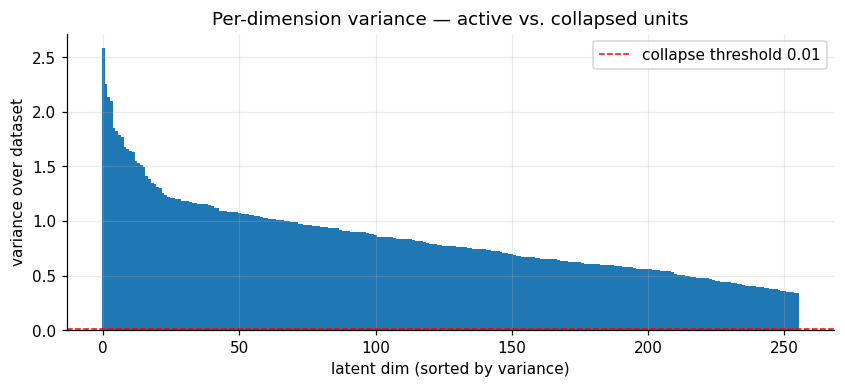

In [19]:
mu, var = Z.mean(0), Z.var(0)
print(f"global mean = {Z.mean():+.3f}  (prior 0)   global std = {Z.std():.3f}  (prior 1)")

THR = 0.01
active = var > THR
print(f"active dims (var > {THR}): {active.sum()} / {LATENT_DIM}")

order = np.argsort(var)[::-1]
plt.figure(figsize=(9, 3.5))
plt.bar(range(LATENT_DIM), var[order], width=1.0)
plt.axhline(THR, color="r", ls="--", lw=1, label=f"collapse threshold {THR}")
plt.xlabel("latent dim (sorted by variance)"); plt.ylabel("variance over dataset")
plt.title("Per-dimension variance — active vs. collapsed units"); plt.legend(); plt.show()

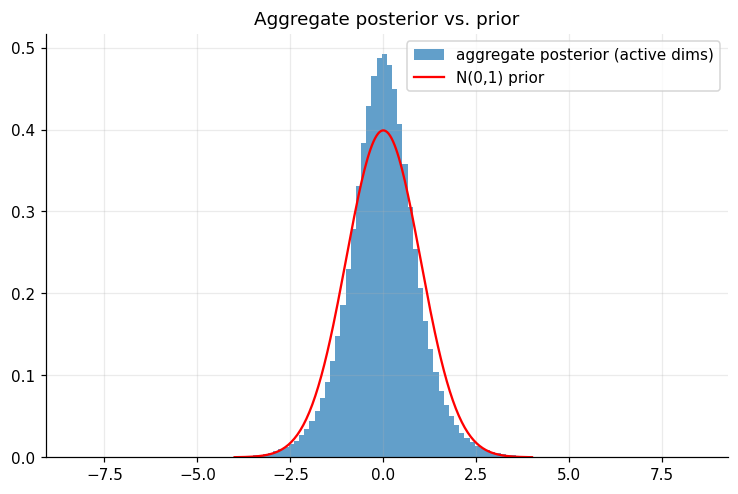

In [20]:
vals = Z[:, active].ravel() if active.any() else Z.ravel()
plt.figure()
plt.hist(vals, bins=120, density=True, alpha=0.7, label="aggregate posterior (active dims)")
xs = np.linspace(-4, 4, 200)
plt.plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2*np.pi), "r", lw=1.5, label="N(0,1) prior")
plt.title("Aggregate posterior vs. prior"); plt.legend(); plt.show()

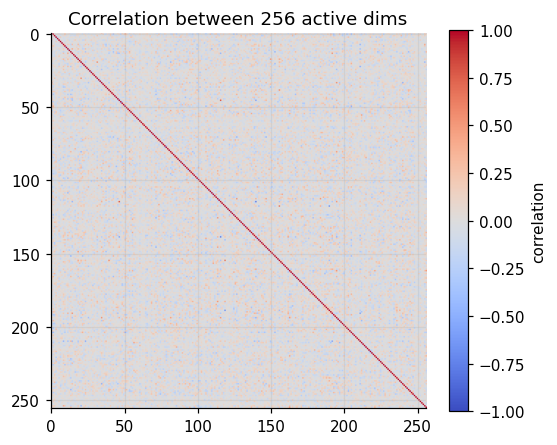

mean |off-diagonal correlation| = 0.073 (low => dims are fairly disentangled)


In [21]:
A = Z[:, active]
C = np.corrcoef(A, rowvar=False)
plt.figure(figsize=(5.5, 4.5))
plt.imshow(C, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="correlation")
plt.title(f"Correlation between {int(active.sum())} active dims"); plt.show()

off = C[~np.eye(C.shape[0], dtype=bool)]
print(f"mean |off-diagonal correlation| = {np.abs(off).mean():.3f} "
      "(low => dims are fairly disentangled)")

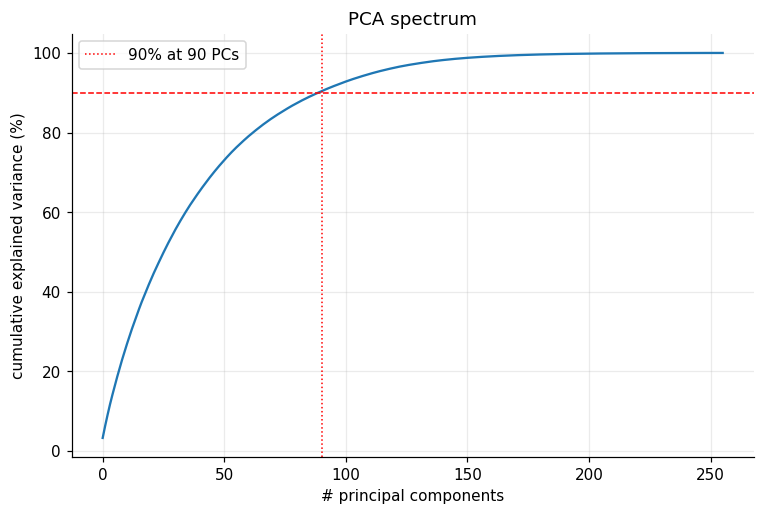

In [22]:
Zs  = StandardScaler().fit_transform(Z)
pca = PCA(random_state=RANDOM_STATE).fit(Zs)
cum = np.cumsum(pca.explained_variance_ratio_) * 100
k90 = int(np.argmax(cum >= 90) + 1)

plt.figure()
plt.plot(cum)
plt.axhline(90, color="r", ls="--", lw=1)
plt.axvline(k90, color="r", ls=":", lw=1, label=f"90% at {k90} PCs")
plt.xlabel("# principal components"); plt.ylabel("cumulative explained variance (%)")
plt.title("PCA spectrum"); plt.legend(); plt.show()

### 2-D maps, coloured per point
PCA is linear; t-SNE / UMAP are non-linear. If gender splits cleanly even in 2-D, expect the linear classifier in §2 to do well.

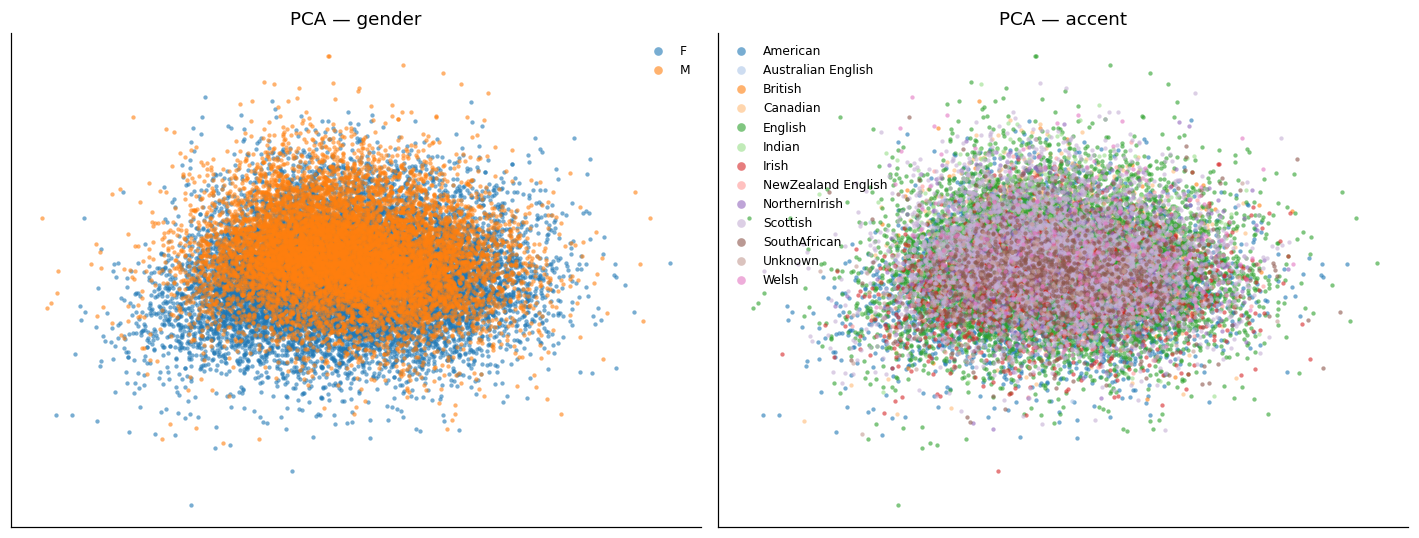

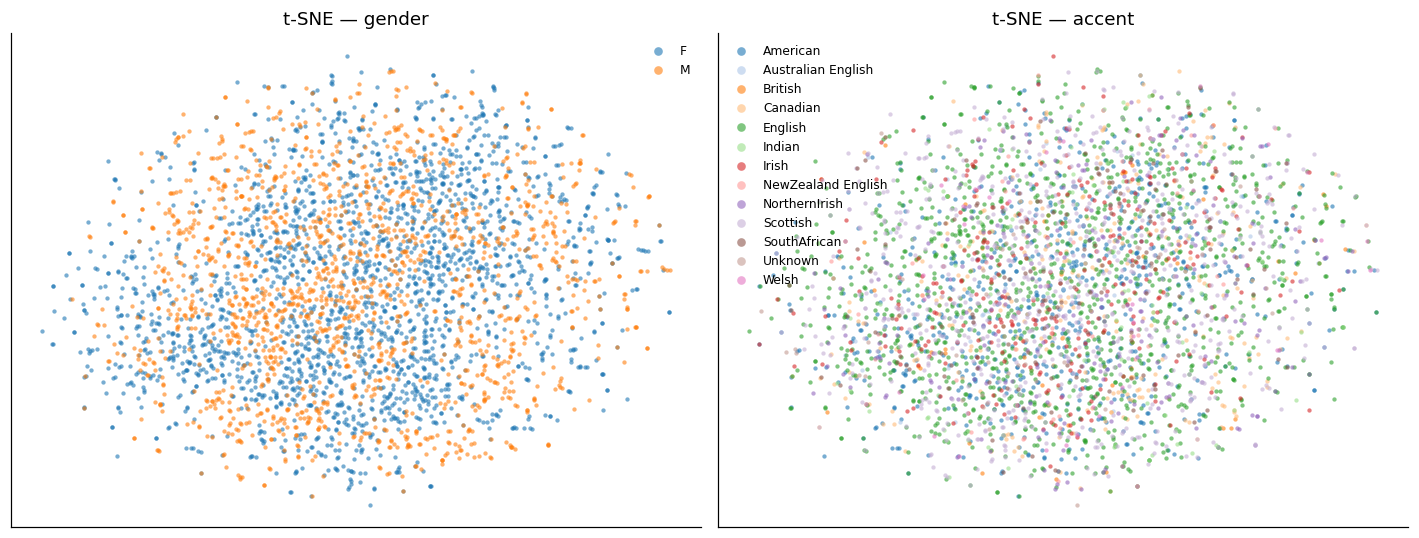

In [10]:
N   = len(Zs)
sub = np.arange(N) if N <= 4000 else rng.choice(N, 4000, replace=False)

emb = {}
emb["PCA"]  = (PCA(2, random_state=RANDOM_STATE).fit_transform(Zs), np.arange(N))
emb["t-SNE"] = (TSNE(2, init="pca", perplexity=30, random_state=RANDOM_STATE)
                .fit_transform(Zs[sub]), sub)
if HAVE_UMAP:
    emb["UMAP"] = (umap.UMAP(n_components=2, random_state=RANDOM_STATE)
                   .fit_transform(Zs), np.arange(N))

for name, (XY, idx) in emb.items():
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    scatter2d(XY, meta.GENDER.iloc[idx],  f"{name} — gender", ax=ax[0])
    scatter2d(XY, meta.ACCENTS.iloc[idx], f"{name} — accent", ax=ax[1])
    plt.tight_layout(); plt.show()

## 2 · Gender — linear latent arithmetic

Two ways to get a **gender direction**, both linear:

* **Difference of class means** $\;v = \mu_{F} - \mu_{M}\;$ — the classic word2vec-style "attribute vector". It lives in raw latent space, so you can *add* it to any point.
* **Logistic-regression weight vector** — the normal to the learned decision hyperplane.

If those two directions point the same way (high cosine similarity), gender is encoded along *one consistent linear axis* — exactly what makes latent arithmetic work.

||gender axis|| = 3.640
AUC of the raw 1-D projection = 0.972


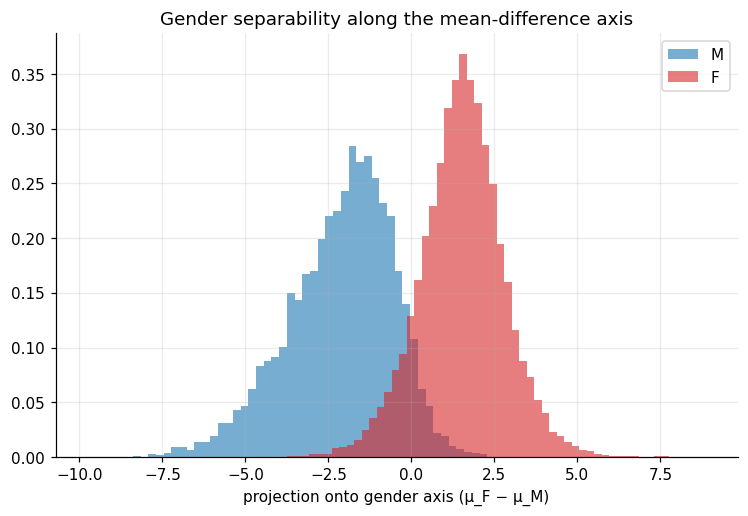

In [23]:
y_gender = (meta.GENDER.str.upper().str[0] == "F").astype(int).to_numpy()  # 1=F, 0=M
groups   = meta.speaker.to_numpy()

mu_f, mu_m = Z[y_gender == 1].mean(0), Z[y_gender == 0].mean(0)
v_gender = mu_f - mu_m
v_unit   = v_gender / np.linalg.norm(v_gender)

proj = (Z - Z.mean(0)) @ v_unit
print(f"||gender axis|| = {np.linalg.norm(v_gender):.3f}")
print(f"AUC of the raw 1-D projection = {roc_auc_score(y_gender, proj):.3f}")

plt.figure()
for c, lab, col in [(0, "M", "#1f77b4"), (1, "F", "#d62728")]:
    plt.hist(proj[y_gender == c], bins=60, density=True, alpha=0.6, color=col, label=lab)
plt.xlabel("projection onto gender axis (μ_F − μ_M)")
plt.title("Gender separability along the mean-difference axis"); plt.legend(); plt.show()

### Honest (speaker-grouped) vs. leaky (random) linear classifier

In [24]:
def cv_predict(X, y, groups, grouped=True, n_splits=5):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    if grouped:
        splits = GroupKFold(n_splits).split(X, y, groups)
    else:
        splits = StratifiedKFold(n_splits, shuffle=True,
                                 random_state=RANDOM_STATE).split(X, y)
    yhat = np.zeros_like(y); yprob = np.zeros(len(y))
    for tr, te in splits:
        clf.fit(X[tr], y[tr])
        yhat[te]  = clf.predict(X[te])
        yprob[te] = clf.predict_proba(X[te])[:, 1]
    return yhat, yprob

yh,  yp  = cv_predict(Z, y_gender, groups, grouped=True)
yhL, _   = cv_predict(Z, y_gender, groups, grouped=False)

print("speaker-grouped  | acc {:.3f}  bal-acc {:.3f}  AUC {:.3f}".format(
    accuracy_score(y_gender, yh), balanced_accuracy_score(y_gender, yh),
    roc_auc_score(y_gender, yp)))
print("random   (LEAKY) | acc {:.3f}  bal-acc {:.3f}".format(
    accuracy_score(y_gender, yhL), balanced_accuracy_score(y_gender, yhL)))
print("\nThe random split is optimistic: it can recognise speakers it also saw in training.")

speaker-grouped  | acc 0.976  bal-acc 0.974  AUC 0.995
random   (LEAKY) | acc 0.978  bal-acc 0.976

The random split is optimistic: it can recognise speakers it also saw in training.


In [25]:
# recover the logistic direction in raw latent space and compare to the mean-diff axis
scaler = StandardScaler().fit(Z)
lr = LogisticRegression(max_iter=2000).fit(scaler.transform(Z), y_gender)
w_raw  = lr.coef_.ravel() / scaler.scale_          # undo standardisation
w_unit = w_raw / np.linalg.norm(w_raw)
print(f"cosine(mean-diff axis, logistic axis) = {float(w_unit @ v_unit):+.3f}")

cosine(mean-diff axis, logistic axis) = +0.643


### Does gender live in the high-fidelity directions?

Same question as we asked for duration (§3.75), now for gender: is the linear gender signal carried by the **high-energy** directions fidelity ranks first, or does it hide in a low-variance direction?

* **Alignment** — $|\cos(\text{gender axis}, \text{PC}_i)|$ against the covariance-PCA basis (recipe of §3.5, on the full `Z`). We use the logistic axis `w_unit`; the mean-difference axis `v_unit` tells the same story since §2 showed they align.
* **Cumulative predictive power** — grouped-CV **AUC** using only the first $k$ energy-ordered PCA directions, overlaid on the fidelity variance curve. R²/AUC saturating early ⇒ gender rides along with the high-fidelity subspace; a long climb ⇒ it draws on low-energy directions fidelity overlooks.

gender axis aligns best with PC21 (|cos|=0.302, 1.49% of variance)
|cos| with PC0 (highest-energy dir): 0.064


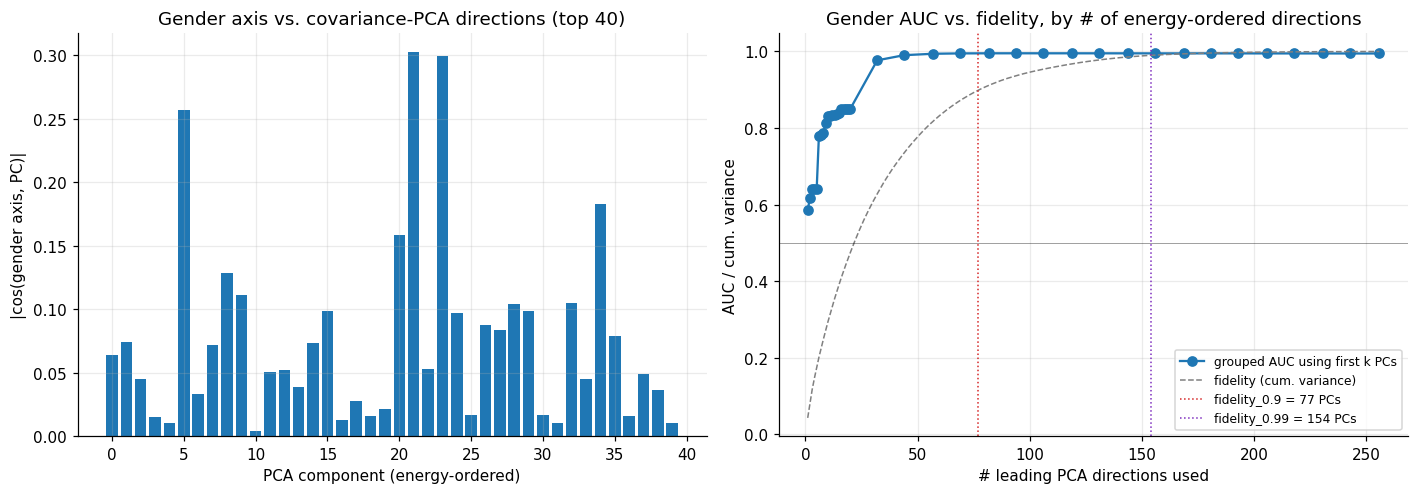

In [26]:
# covariance-PCA basis on full Z (same recipe as §3.5), reused below
pca_full = PCA(Z.shape[1], random_state=RANDOM_STATE).fit(Z - Z.mean(0))
comps_full   = pca_full.components_
evr_cum_full = np.cumsum(pca_full.explained_variance_ratio_)
Zp_full      = (Z - Z.mean(0)) @ comps_full.T          # latents in energy-ordered PCA coords

def cumulative_score(Zp, y, groups, score_fn, n_splits=5, proba=False, ks=None):
    """Grouped-CV score using only the first k PCA directions, for a grid of k."""
    if ks is None:
        D = Zp.shape[1]
        ks = np.unique(np.clip(np.r_[np.arange(1, 21),
                       np.linspace(20, D, 20).astype(int)], 1, D))
    scores = []
    for k in ks:
        pred = np.zeros(len(y), dtype=float)
        for tr, te in GroupKFold(n_splits).split(Zp[:, :k], y, groups):
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
            clf.fit(Zp[tr, :k], y[tr])
            pred[te] = clf.predict_proba(Zp[te, :k])[:, 1] if proba else clf.predict(Zp[te, :k])
        scores.append(score_fn(y, pred))
    return ks, np.array(scores)

# view 1: alignment of the gender axis with each PC
cos_g = np.abs(comps_full @ w_unit)
K = 40; bestg = int(np.argmax(cos_g))
print(f"gender axis aligns best with PC{bestg} (|cos|={cos_g[bestg]:.3f}, "
      f"{pca_full.explained_variance_ratio_[bestg]*100:.2f}% of variance)")
print(f"|cos| with PC0 (highest-energy dir): {cos_g[0]:.3f}")

# view 2: cumulative grouped AUC using first k PCs
ksg, auc_k = cumulative_score(Zp_full, y_gender, groups, roc_auc_score, proba=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].bar(range(K), cos_g[:K])
ax[0].set_xlabel("PCA component (energy-ordered)"); ax[0].set_ylabel("|cos(gender axis, PC)|")
ax[0].set_title(f"Gender axis vs. covariance-PCA directions (top {K})")
ax[1].plot(ksg, auc_k, "o-", lw=1.5, label="grouped AUC using first k PCs")
ax[1].plot(np.arange(1, len(evr_cum_full) + 1), evr_cum_full, color="gray", ls="--", lw=1,
           label="fidelity (cum. variance)")
for p, col in [(.9, "#d62728"), (.99, "#7f2fbf")]:
    kf = int(np.argmax(evr_cum_full > p))
    ax[1].axvline(kf, color=col, ls=":", lw=1, label=f"fidelity_{p} = {kf} PCs")
ax[1].axhline(0.5, color="k", ls="-", lw=0.6, alpha=0.4)
ax[1].set_xlabel("# leading PCA directions used"); ax[1].set_ylabel("AUC / cum. variance")
ax[1].set_title("Gender AUC vs. fidelity, by # of energy-ordered directions")
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### Latent arithmetic: traverse the gender direction

Walk a handful of points along $z + \alpha\,\sigma\,\hat v$ and watch the classifier's $P(\text{Female})$ slide across the boundary. The attribute moves *linearly* — adding the vector is enough to change the prediction.

If you still have the VAE decoder loaded you can decode any shifted `z` back to audio to actually **hear** the change (hook at the bottom of the cell).

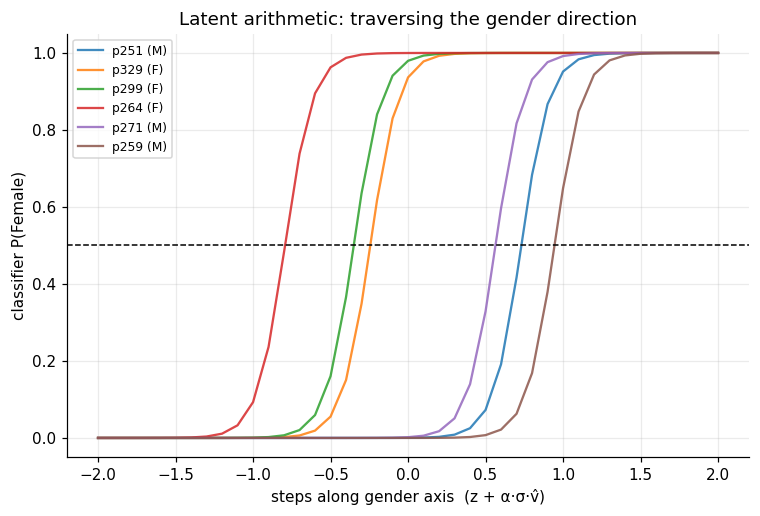

In [14]:
step  = v_unit * proj.std()                 # one step ≈ 1 std along the axis
alpha = np.linspace(-2, 2, 41)
picks = rng.choice(len(Z), 6, replace=False)

plt.figure()
for i in picks:
    zs = Z[i][None, :] + alpha[:, None] * step[None, :]
    p  = lr.predict_proba(scaler.transform(zs))[:, 1]
    plt.plot(alpha, p, alpha=0.85,
             label=f"{meta.speaker[i]} ({'F' if y_gender[i] else 'M'})")
plt.axhline(0.5, color="k", ls="--", lw=1)
plt.xlabel("steps along gender axis  (z + α·σ·v̂)")
plt.ylabel("classifier P(Female)")
plt.title("Latent arithmetic: traversing the gender direction")
plt.legend(fontsize=8); plt.show()

# --- OPTIONAL: decode a shifted latent back to audio ---
# from src.model import load_vae            # your decoder
# vae = load_vae(...)
# z_shift = Z[picks[0]] + 1.5 * step
# audio = vae.decode(torch.tensor(z_shift)[None].to(device))
# import IPython.display as ipd; ipd.Audio(audio.squeeze().cpu().numpy(), rate=SR)

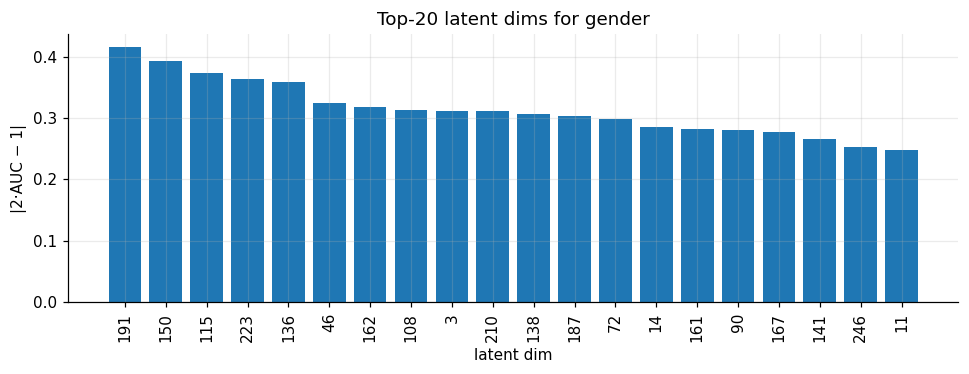

In [15]:
# which dims carry gender? per-dim |2·AUC − 1|
dim_auc = np.array([roc_auc_score(y_gender, Z[:, d]) for d in range(LATENT_DIM)])
imp = np.abs(dim_auc - 0.5) * 2
top = np.argsort(imp)[::-1][:20]

plt.figure(figsize=(9, 3.5))
plt.bar(range(20), imp[top])
plt.xticks(range(20), top, rotation=90)
plt.xlabel("latent dim"); plt.ylabel("|2·AUC − 1|")
plt.title("Top-20 latent dims for gender"); plt.tight_layout(); plt.show()

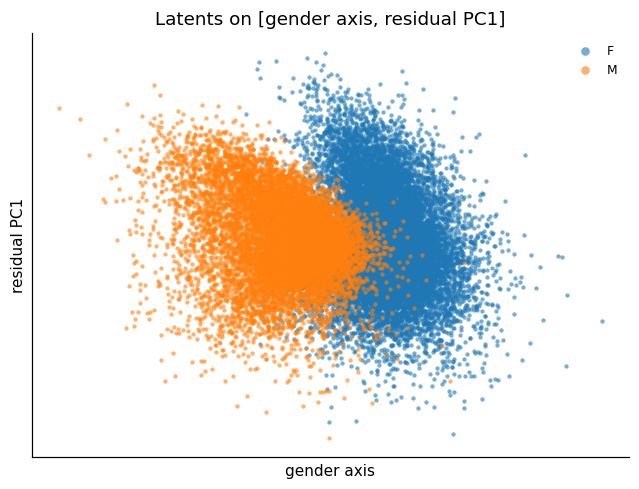

In [16]:
# a clean "per-point" view: x = gender axis, y = leading PC of the residual
Zc    = Z - Z.mean(0)
resid = Zc - np.outer(Zc @ v_unit, v_unit)
y2    = PCA(1, random_state=RANDOM_STATE).fit_transform(resid).ravel()

plt.figure(figsize=(7, 5))
scatter2d(np.column_stack([proj, y2]), meta.GENDER,
          "Latents on [gender axis, residual PC1]")
plt.xlabel("gender axis"); plt.ylabel("residual PC1"); plt.show()

## 3 · Accent

Harder than gender: multi-class and **heavily imbalanced** (VCTK is mostly English/Scottish). So:

* keep only accents with enough *distinct speakers* for grouped CV to be meaningful,
* report **balanced accuracy** and per-class metrics, not raw accuracy,
* compare against both uniform chance and the by-frequency baseline.

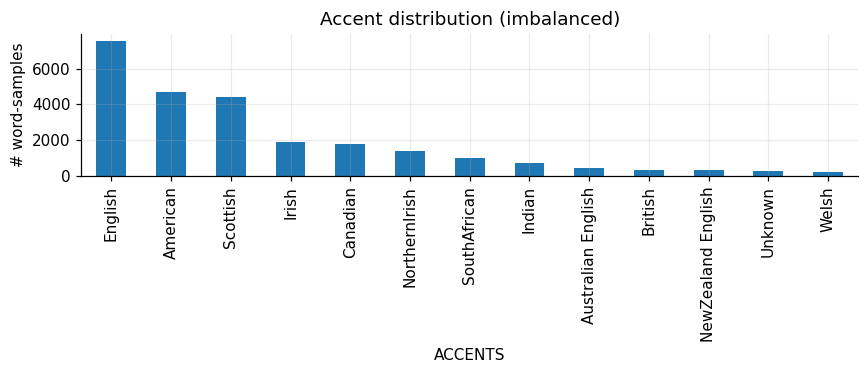

ACCENTS
English               7570
American              4705
Scottish              4394
Irish                 1883
Canadian              1756
NorthernIrish         1356
SouthAfrican           985
Indian                 704
Australian English     441
British                323
NewZealand English     291
Unknown                256
Welsh                  208
Name: count, dtype: int64


In [27]:
acc_counts = meta.ACCENTS.value_counts()
plt.figure(figsize=(8, 3.5))
acc_counts.plot.bar()
plt.ylabel("# word-samples"); plt.title("Accent distribution (imbalanced)")
plt.tight_layout(); plt.show()
print(acc_counts)

In [28]:
MIN_SPK = 3
spk_per_acc = meta.groupby("ACCENTS").speaker.nunique()
keep_acc = spk_per_acc[spk_per_acc >= MIN_SPK].index
mask = meta.ACCENTS.isin(keep_acc).to_numpy()
print(f"keeping accents with >= {MIN_SPK} speakers:", list(keep_acc))

Za = Z[mask]
ma = meta.loc[mask].reset_index(drop=True)
le = LabelEncoder().fit(ma.ACCENTS)
yA = le.transform(ma.ACCENTS)
ga = ma.speaker.to_numpy()

keeping accents with >= 3 speakers: ['American', 'Canadian', 'English', 'Indian', 'Irish', 'NorthernIrish', 'Scottish', 'SouthAfrican']


In [29]:
n_splits = max(2, min(5, int(spk_per_acc[keep_acc].min())))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

yhat = np.empty_like(yA)
for tr, te in GroupKFold(n_splits).split(Za, yA, ga):
    clf.fit(Za[tr], yA[tr])
    yhat[te] = clf.predict(Za[te])

freq = pd.Series(yA).value_counts(normalize=True)
print(f"accent — speaker-grouped {n_splits}-fold")
print(f"  accuracy      {accuracy_score(yA, yhat):.3f}")
print(f"  balanced acc  {balanced_accuracy_score(yA, yhat):.3f}")
print(f"  chance        {1/len(le.classes_):.3f} uniform / {(freq**2).sum():.3f} by-frequency\n")
print(classification_report(yA, yhat, target_names=le.classes_))

accent — speaker-grouped 3-fold
  accuracy      0.260
  balanced acc  0.133
  chance        0.125 uniform / 0.199 by-frequency

               precision    recall  f1-score   support

     American       0.24      0.28      0.26      4705
     Canadian       0.07      0.03      0.04      1756
      English       0.32      0.47      0.38      7570
       Indian       0.01      0.01      0.01       704
        Irish       0.06      0.02      0.03      1883
NorthernIrish       0.01      0.00      0.00      1356
     Scottish       0.30      0.26      0.28      4394
 SouthAfrican       0.00      0.00      0.00       985

     accuracy                           0.26     23353
    macro avg       0.13      0.13      0.12     23353
 weighted avg       0.22      0.26      0.23     23353



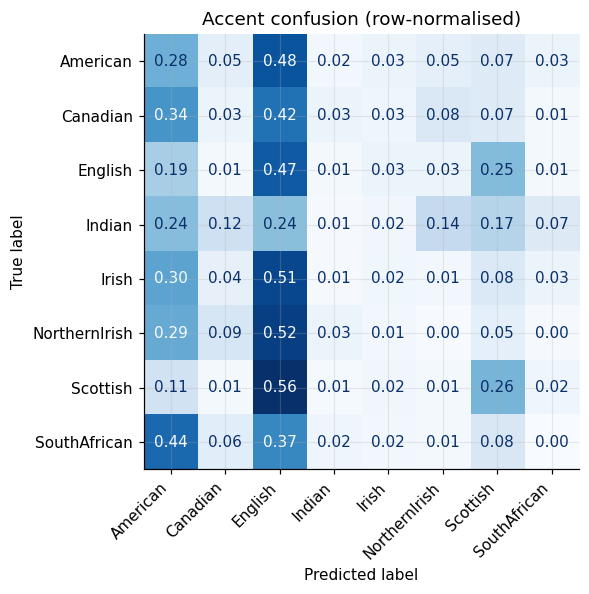

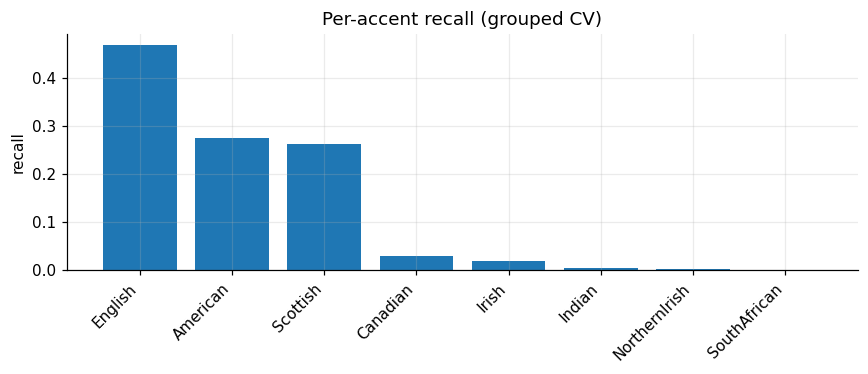

In [30]:
cm = confusion_matrix(yA, yhat, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
plt.xticks(rotation=45, ha="right")
plt.title("Accent confusion (row-normalised)"); plt.tight_layout(); plt.show()

recall = np.diag(cm); o = np.argsort(recall)[::-1]
plt.figure(figsize=(8, 3.5))
plt.bar(range(len(recall)), recall[o])
plt.xticks(range(len(recall)), le.classes_[o], rotation=45, ha="right")
plt.ylabel("recall"); plt.title("Per-accent recall (grouped CV)")
plt.tight_layout(); plt.show()

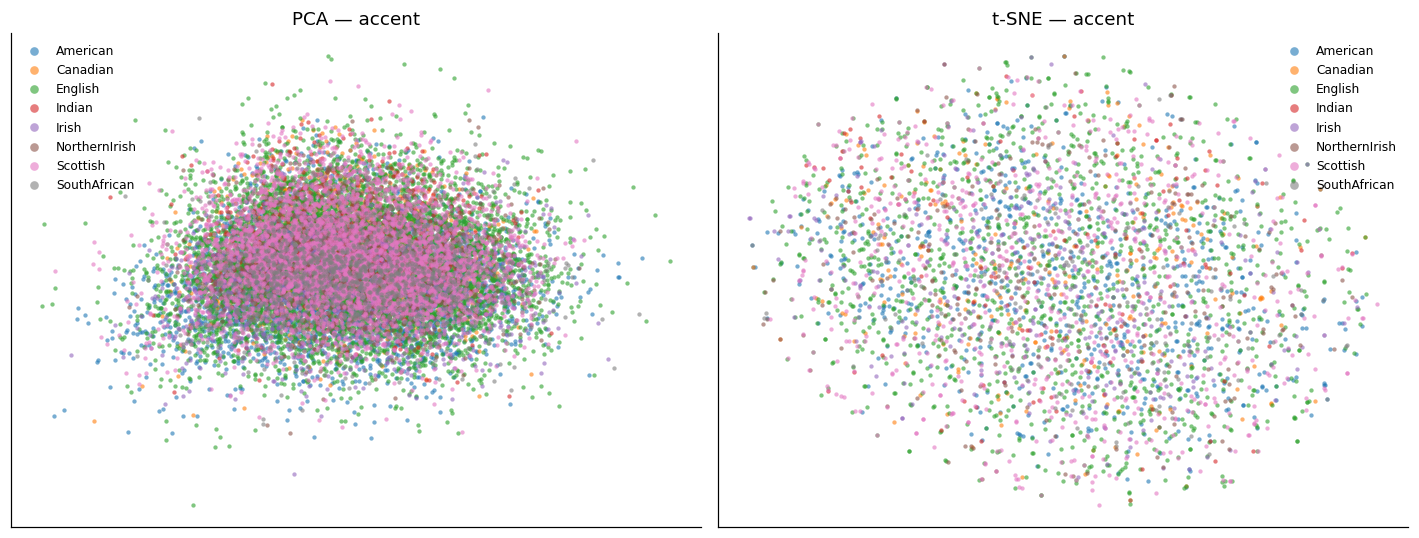

In [21]:
# 2-D maps coloured by accent (kept classes only)
Zas = StandardScaler().fit_transform(Za)
Na  = len(Zas); suba = np.arange(Na) if Na <= 4000 else rng.choice(Na, 4000, replace=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
scatter2d(PCA(2, random_state=RANDOM_STATE).fit_transform(Zas),
          ma.ACCENTS, "PCA — accent", ax=ax[0])
scatter2d(TSNE(2, init="pca", perplexity=30, random_state=RANDOM_STATE).fit_transform(Zas[suba]),
          ma.ACCENTS.iloc[suba], "t-SNE — accent", ax=ax[1])
plt.tight_layout(); plt.show()

### Does accent live in the high-fidelity directions?

Accent is multi-class, so there's no single "accent axis" to take a cosine with. Two adapted views, both against a covariance-PCA basis recomputed on the kept-accent subset `Za` (§3.5 recipe, matched sample set):

* **Per-PC separability** — the one-way ANOVA **F-score** of each PCA direction against the accent label (how much that single direction separates the classes). Plotting F-score against the energy-ordered PCs shows whether the discriminative directions are the high-energy ones.
* **Cumulative predictive power** — grouped-CV **balanced accuracy** using the first $k$ energy-ordered PCs, overlaid on the fidelity variance curve (balanced accuracy since accent is imbalanced; compare to the uniform-chance line).

most accent-discriminative PC = PC0 (F=184.1, 4.31% of variance)


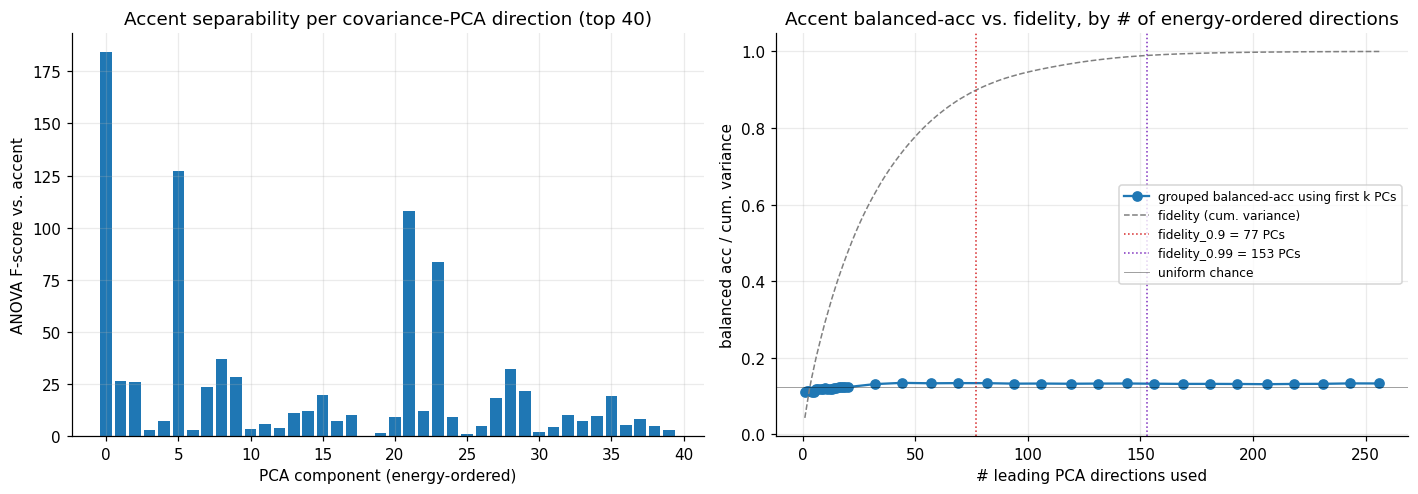

In [31]:
from sklearn.feature_selection import f_classif

# covariance-PCA on the kept-accent subset (§3.5 recipe, on Za)
pca_a = PCA(Za.shape[1], random_state=RANDOM_STATE).fit(Za - Za.mean(0))
comps_a   = pca_a.components_
evr_cum_a = np.cumsum(pca_a.explained_variance_ratio_)
Zpa       = (Za - Za.mean(0)) @ comps_a.T

# view 1: per-PC accent separability (ANOVA F-score of each PCA direction)
F, _ = f_classif(Zpa, yA)
K = 40; besta = int(np.argmax(F))
print(f"most accent-discriminative PC = PC{besta} (F={F[besta]:.1f}, "
      f"{pca_a.explained_variance_ratio_[besta]*100:.2f}% of variance)")

# view 2: cumulative grouped balanced accuracy using first k PCs
na = max(2, min(5, int(spk_per_acc[keep_acc].min())))
D = Za.shape[1]
ksa = np.unique(np.clip(np.r_[np.arange(1, 21), np.linspace(20, D, 20).astype(int)], 1, D))
bacc_k = []
for k in ksa:
    yhat = np.empty_like(yA)
    for tr, te in GroupKFold(na).split(Zpa[:, :k], yA, ga):
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
        clf.fit(Zpa[tr, :k], yA[tr]); yhat[te] = clf.predict(Zpa[te, :k])
    bacc_k.append(balanced_accuracy_score(yA, yhat))
bacc_k = np.array(bacc_k)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].bar(range(K), F[:K])
ax[0].set_xlabel("PCA component (energy-ordered)"); ax[0].set_ylabel("ANOVA F-score vs. accent")
ax[0].set_title(f"Accent separability per covariance-PCA direction (top {K})")
ax[1].plot(ksa, bacc_k, "o-", lw=1.5, label="grouped balanced-acc using first k PCs")
ax[1].plot(np.arange(1, len(evr_cum_a) + 1), evr_cum_a, color="gray", ls="--", lw=1,
           label="fidelity (cum. variance)")
for p, col in [(.9, "#d62728"), (.99, "#7f2fbf")]:
    kf = int(np.argmax(evr_cum_a > p))
    ax[1].axvline(kf, color=col, ls=":", lw=1, label=f"fidelity_{p} = {kf} PCs")
ax[1].axhline(1 / len(le.classes_), color="k", ls="-", lw=0.6, alpha=0.4, label="uniform chance")
ax[1].set_xlabel("# leading PCA directions used"); ax[1].set_ylabel("balanced acc / cum. variance")
ax[1].set_title("Accent balanced-acc vs. fidelity, by # of energy-ordered directions")
ax[1].legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()

## 3.5 · Fidelity — RAVE-style latent dimensionality

RAVE measures the *effective* size of its latent with a quantity it calls **fidelity**
(`RAVE/rave/model.py`, `validation_epoch_end`): a covariance-PCA over the latents,
then the cumulative explained-variance curve.

1. Subtract the global mean (`latent_mean`); **no per-dim scaling** (covariance PCA, not correlation PCA — the key difference from the §1 spectrum, which standardises first).
2. Fit full PCA; `fidelity[i] = cumsum(explained_variance_ratio)[i]` — the fraction of variance captured by the first `i+1` components.
3. Report, for `p ∈ {0.8, 0.9, 0.95, 0.99}`, `argmax(fidelity > p)` — the number of PCA directions needed to reach that fraction. RAVE logs these as `fidelity_0.8`, … each validation epoch.

A low `fidelity_0.95` means the latent really lives on a low-dimensional manifold (the encoder packs the signal into a few directions); a high one means variance is spread across many dims. This is purely a property of the *latents*, independent of the gender/accent labels above.

> **One deviation from RAVE.** RAVE has a *temporal* latent and pools over every time-step — it fits PCA on `rearrange(z, "b c t -> (b t) c")`, so each frame is a sample. This model uses **fixed-length, length-1 latents** (one vector per clip), so the natural sample unit is the clip and we fit PCA directly on `Z` — the same `(n_samples, C)` matrix, just with `n_samples = n_clips` instead of `n_clips · T`. The formula is identical; only what counts as a "sample" differs.

RAVE fidelity (PCs needed to reach variance fraction):
  fidelity_0.8:   53 / 256 dims
  fidelity_0.9:   77 / 256 dims
  fidelity_0.95:  103 / 256 dims
  fidelity_0.99:  154 / 256 dims


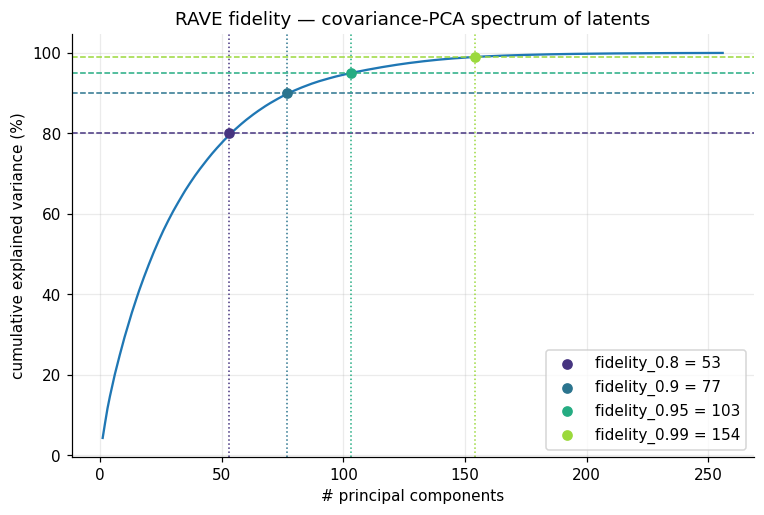

In [22]:
# --- RAVE fidelity: covariance PCA on mean-centred latents, cumulative EVR ---
# Length-1 latents => one vector per clip, so Z is already the sample matrix
# (RAVE's `rearrange(z, "b c t -> (b t) c")` reduces to this when T == 1).
latent_mean = Z.mean(0)                                  # == self.latent_mean
pca_fid = PCA(Z.shape[-1], random_state=RANDOM_STATE).fit(Z - latent_mean)
fidelity = np.cumsum(pca_fid.explained_variance_ratio_)  # == self.fidelity

var_percent = [.8, .9, .95, .99]
fidelity_at = {p: int(np.argmax(fidelity > p)) for p in var_percent}
print("RAVE fidelity (PCs needed to reach variance fraction):")
for p in var_percent:
    print(f"  fidelity_{p}: {fidelity_at[p]:4d} / {LATENT_DIM} dims")

# --- plot the cumulative curve with the threshold markers ---
plt.figure()
plt.plot(np.arange(1, len(fidelity) + 1), fidelity * 100, lw=1.5)
colors = plt.get_cmap("viridis")(np.linspace(0.15, 0.85, len(var_percent)))
for p, col in zip(var_percent, colors):
    k = fidelity_at[p]
    plt.axhline(p * 100, color=col, ls="--", lw=1)
    plt.axvline(k, color=col, ls=":", lw=1)
    plt.scatter([k], [fidelity[k] * 100], color=col, zorder=5,
                label=f"fidelity_{p} = {k}")
plt.xlabel("# principal components"); plt.ylabel("cumulative explained variance (%)")
plt.title("RAVE fidelity — covariance-PCA spectrum of latents")
plt.legend(loc="lower right"); plt.show()

> **Covariance-PCA vs. correlation-PCA — why the notebook uses both.** Both are eigendecompositions, but of different matrices. **Covariance-PCA** (here, fidelity) centres only, so each dim keeps its native scale — a dim with variance 5 pulls 5× harder than one with variance 1. **Correlation-PCA** (the §1 spectrum, via `StandardScaler`) divides each dim by its std first, forcing every dim to variance 1, so all contribute equally regardless of scale.
>
> They answer different questions, so mixing them is deliberate, not sloppy:
>
> - **Fidelity *must* be covariance-PCA.** It measures the *effective dimensionality of the latent as it exists* — the point is that high-variance dims dominate and near-collapsed dims contribute little. Standardising first would inflate every collapsed dim (variance ≈ 0) up to variance 1 and make the latent look artificially high-dimensional, destroying exactly what fidelity quantifies.
> - **The §1 spectrum uses correlation-PCA** as a *complementary* view: it sits next to the per-dim variance bar chart, which already tells the raw-energy story, so standardising there answers the different question "how many *correlated directions* are there, ignoring which dims happen to be loud." (Want §1 and §3.5 to tell one consistent energy story? Drop the `StandardScaler` in the §1 PCA cell — it's a one-line change.)
> - **The `StandardScaler` in the §2/§3 classifiers is a separate matter entirely** — not a PCA choice. It's there so L2-regularised logistic regression penalises every dim's coefficient *fairly* (otherwise the penalty is scale-dependent) and so the solver converges. Leave it.
>
> Rule of thumb: **covariance-PCA when a dim's scale is itself the signal** (fidelity, energy, effective dimensionality); **standardise-first when you want scale-invariant structure or fair per-feature regularisation** (the §1 spectrum, classifier inputs).

## 3.75 · Duration — linear regression from the latents

Gender and accent are *speaker* attributes; **duration is a property of the individual word-utterance** (`duration` column in `labels.csv`, in seconds — how long the clip lasts). So it's a natural per-sample regression target: can the latent linearly predict how long the word was?

This mirrors §2/§3 but swaps classification for regression:

* **Ridge regression** (L2-regularised linear) latent → duration, reported with **R²** and **MAE** (seconds).
* **Honest vs. leaky CV.** Duration is per-sample, so a random split can't leak the label the way it did for gender/accent. But a speaker's clips still share timbre and speaking pace, so **speaker-grouped** CV is the honest measure — a random split lets the model lean on speaker-specific cues it won't have at test time. We show both.
* **Baseline.** Compare R² against predict-the-global-mean (R² = 0 by construction) and MAE against the mean-absolute-deviation baseline. Ridge is only meaningful if it beats them.

> Duration joins by `sample_id` (per-utterance), not by speaker — a handful of clips may not match `labels.csv` and are dropped for this section only, keeping `Zd`/`dur` aligned. `Z` and `meta` from §0 are untouched.

24872 samples | duration (s): mean 0.323  std 0.161  range [0.16, 0.96]


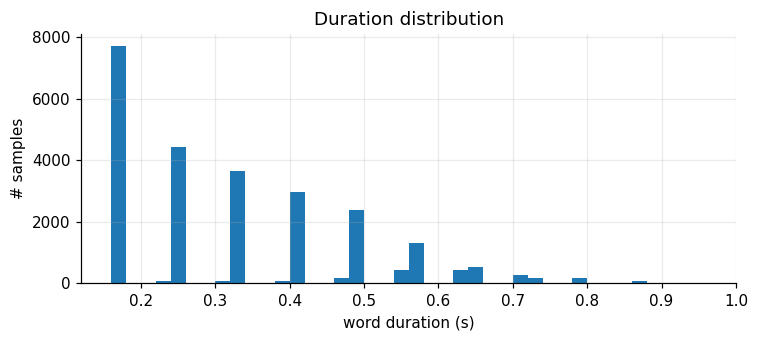

In [10]:
# --- build the duration target, joined per-utterance via sample_id ---
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import r2_score, mean_absolute_error

_key = pd.Series([os.path.splitext(os.path.basename(str(f)))[0] for f in encoded.filenames])
_dur_map = labels.drop_duplicates("sample_id").set_index("sample_id")["duration"]
_dur_all = _key.map(_dur_map).to_numpy(dtype=float)          # aligned to ORIGINAL encoded order

# §0 already dropped samples with no speaker match (Z/meta), but did so on the
# post-filter index; realign duration to the current Z/meta by sample_id instead.
dur_series = meta["filename"].map(
    lambda f: _dur_map.get(os.path.splitext(os.path.basename(str(f)))[0], np.nan)
)
have = dur_series.notna().to_numpy()
n_drop = int((~have).sum())
if n_drop:
    print(f"{n_drop} samples had no duration in labels.csv -> dropping for this section.")

Zd   = Z[have]
dur  = dur_series[have].to_numpy(dtype=float)
gd   = meta.speaker.to_numpy()[have]

print(f"{len(dur)} samples | duration (s): "
      f"mean {dur.mean():.3f}  std {dur.std():.3f}  range [{dur.min():.2f}, {dur.max():.2f}]")

plt.figure(figsize=(7, 3.2))
plt.hist(dur, bins=40); plt.xlabel("word duration (s)"); plt.ylabel("# samples")
plt.title("Duration distribution"); plt.tight_layout(); plt.show()

In [11]:
def cv_regress(X, y, groups, grouped=True, n_splits=5):
    reg = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    if grouped:
        splits = GroupKFold(n_splits).split(X, y, groups)
    else:
        splits = KFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(X)
    yhat = np.zeros_like(y, dtype=float)
    for tr, te in splits:
        reg.fit(X[tr], y[tr])
        yhat[te] = reg.predict(X[te])
    return yhat

yh  = cv_regress(Zd, dur, gd, grouped=True)
yhL = cv_regress(Zd, dur, gd, grouped=False)

mae_base = np.abs(dur - dur.mean()).mean()   # predict-the-mean baseline
print("duration regression (latent -> seconds):")
print("  speaker-grouped  | R2 {:+.3f}  MAE {:.3f}s".format(
    r2_score(dur, yh), mean_absolute_error(dur, yh)))
print("  random   (LEAKY) | R2 {:+.3f}  MAE {:.3f}s".format(
    r2_score(dur, yhL), mean_absolute_error(dur, yhL)))
print("  baseline (mean)  | R2 {:+.3f}  MAE {:.3f}s".format(0.0, mae_base))
print("\nGrouped R2 is the honest number; the leaky gap shows how much the model"
      "\nrelies on speaker-specific pacing cues it won't have on unseen speakers.")

duration regression (latent -> seconds):
  speaker-grouped  | R2 +0.965  MAE 0.023s
  random   (LEAKY) | R2 +0.965  MAE 0.023s
  baseline (mean)  | R2 +0.000  MAE 0.133s

Grouped R2 is the honest number; the leaky gap shows how much the model
relies on speaker-specific pacing cues it won't have on unseen speakers.


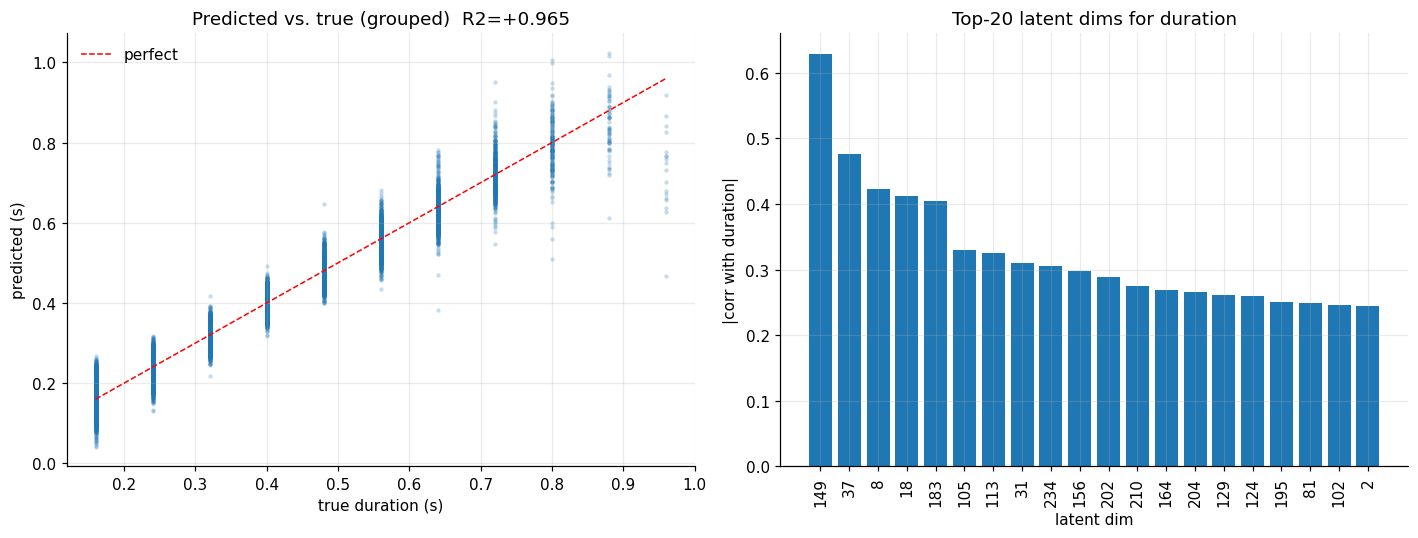

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# predicted vs. true (speaker-grouped, honest)
lim = [dur.min(), dur.max()]
ax[0].scatter(dur, yh, s=8, alpha=0.25, linewidths=0)
ax[0].plot(lim, lim, "r--", lw=1, label="perfect")
ax[0].set_xlabel("true duration (s)"); ax[0].set_ylabel("predicted (s)")
ax[0].set_title(f"Predicted vs. true (grouped)  R2={r2_score(dur, yh):+.3f}")
ax[0].legend(frameon=False)

# per-dim linear importance: |corr(latent dim, duration)|
dur_c = dur - dur.mean()
Zc    = Zd - Zd.mean(0)
denom = (np.linalg.norm(Zc, axis=0) * np.linalg.norm(dur_c)) + 1e-12
corr  = (Zc * dur_c[:, None]).sum(0) / denom
top   = np.argsort(np.abs(corr))[::-1][:20]
ax[1].bar(range(20), np.abs(corr)[top])
ax[1].set_xticks(range(20)); ax[1].set_xticklabels(top, rotation=90)
ax[1].set_xlabel("latent dim"); ax[1].set_ylabel("|corr with duration|")
ax[1].set_title("Top-20 latent dims for duration")
plt.tight_layout(); plt.show()

### Does duration live in the high-fidelity directions?

§3.5 ranks latent directions by *energy* (covariance-PCA — the ones fidelity counts first). §3.75 finds the direction that best *predicts duration* (the Ridge axis). Natural question: **is the duration signal carried by the high-variance directions the encoder spends most of its bits on, or does it hide in a low-energy direction fidelity would rank near the bottom?**

Two views, both against the covariance-PCA basis recomputed on the duration-matched samples (same recipe as §3.5, just restricted to `Zd` so the sample sets match exactly):

* **Alignment** — $|\cos(\text{duration axis}, \text{PC}_i)|$ for the leading PCs. A spike at PC $i$ means "duration ≈ the $i$-th highest-energy direction." Spikes at small $i$ ⇒ duration is a high-fidelity direction; spikes at large $i$ ⇒ it's low-energy.
* **Cumulative predictive power** — R² of a duration regression using only the first $k$ PCA directions as features, plotted against the fidelity variance curve. If R² saturates within the first few PCs, the duration signal is concentrated in the high-energy subspace (it rides along with fidelity). If R² keeps climbing well past `fidelity_0.9`, duration draws on directions that carry little variance — cheap for the encoder to encode, easy for fidelity to overlook.

duration axis aligns best with PC254 (|cos|=0.296, that PC carries 0.00% of variance)
|cos| with PC0 (highest-energy dir): 0.027


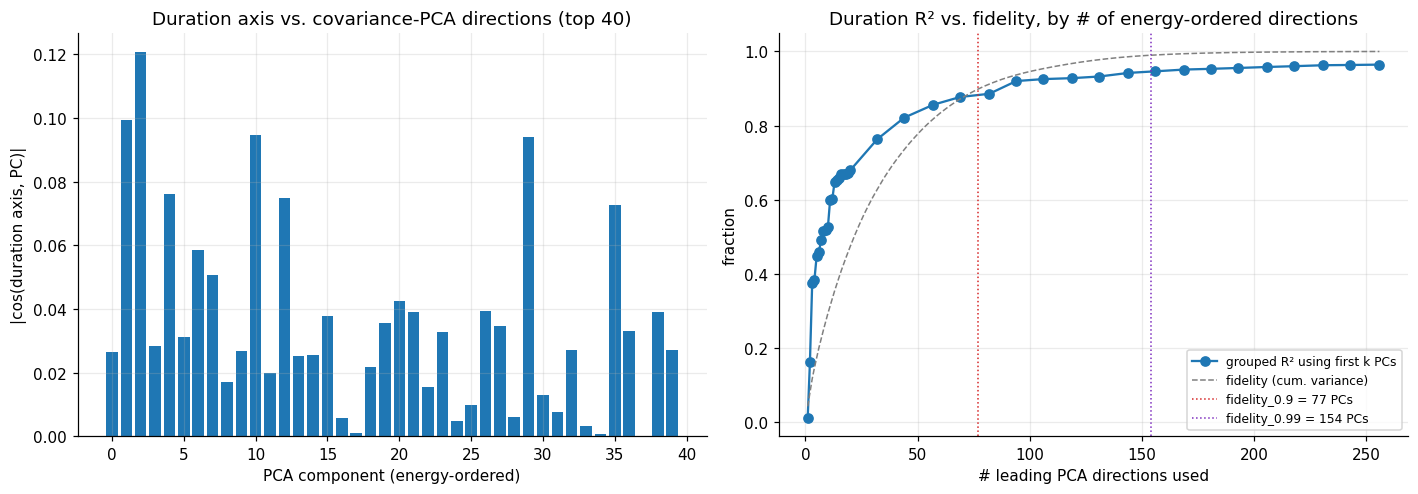

In [13]:
# covariance-PCA on the duration-matched samples (same recipe as §3.5, on Zd)
pca_d = PCA(Zd.shape[1], random_state=RANDOM_STATE).fit(Zd - Zd.mean(0))
comps    = pca_d.components_                      # (n_pc, D), unit rows, energy-ordered
evr_cum  = np.cumsum(pca_d.explained_variance_ratio_)

# duration axis = Ridge weights mapped back to raw latent space (undo StandardScaler)
_sc = StandardScaler().fit(Zd)
_rg = Ridge(alpha=1.0).fit(_sc.transform(Zd), dur)
w_raw  = _rg.coef_ / _sc.scale_
w_unit = w_raw / np.linalg.norm(w_raw)

# --- view 1: |cos(duration axis, PC_i)| ---
cos_pc = np.abs(comps @ w_unit)                   # unit rows . unit vector
K = 40                                            # leading PCs to show
best = int(np.argmax(cos_pc))
print(f"duration axis aligns best with PC{best} "
      f"(|cos|={cos_pc[best]:.3f}, that PC carries "
      f"{pca_d.explained_variance_ratio_[best]*100:.2f}% of variance)")
print(f"|cos| with PC0 (highest-energy dir): {cos_pc[0]:.3f}")

# --- view 2: cumulative R2 using only the first k PCA directions ---
Zp = (Zd - Zd.mean(0)) @ comps.T                  # latents in PCA coords, energy-ordered
ks = np.unique(np.clip(np.r_[np.arange(1, 21), np.linspace(20, Zd.shape[1], 20).astype(int)],
                       1, Zd.shape[1]))
r2_k = []
for k in ks:
    yh = np.zeros_like(dur)
    for tr, te in GroupKFold(5).split(Zp[:, :k], dur, gd):
        reg = Ridge(alpha=1.0).fit(Zp[tr, :k], dur[tr])
        yh[te] = reg.predict(Zp[te, :k])
    r2_k.append(r2_score(dur, yh))
r2_k = np.array(r2_k)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].bar(range(K), cos_pc[:K])
ax[0].set_xlabel("PCA component (energy-ordered)"); ax[0].set_ylabel("|cos(duration axis, PC)|")
ax[0].set_title(f"Duration axis vs. covariance-PCA directions (top {K})")

ax[1].plot(ks, r2_k, "o-", lw=1.5, label="grouped R² using first k PCs")
ax[1].plot(np.arange(1, len(evr_cum) + 1), evr_cum, color="gray", ls="--", lw=1,
           label="fidelity (cum. variance)")
for p, col in [(.9, "#d62728"), (.99, "#7f2fbf")]:
    kf = int(np.argmax(evr_cum > p))
    ax[1].axvline(kf, color=col, ls=":", lw=1, label=f"fidelity_{p} = {kf} PCs")
ax[1].set_xlabel("# leading PCA directions used"); ax[1].set_ylabel("fraction")
ax[1].set_title("Duration R² vs. fidelity, by # of energy-ordered directions")
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 3.9 · Silhouette scores — do the labels form latent clusters?

The classifiers in §2/§3 ask *"is a label linearly decodable?"*. Silhouette asks a different, unsupervised question: **do points sharing a label actually sit closer together in the latent than to points of other labels?** For each point it compares mean intra-label distance $a$ to mean nearest-other-label distance $b$, giving $(b-a)/\max(a,b) \in [-1, 1]$: **~1** tight well-separated label clusters, **~0** labels don't correspond to geometry, **<0** points are on average closer to the *wrong* label.

Computed on standardised latents (same scaling as the classifier inputs), on a fixed random subsample (silhouette is $O(n^2)$ in memory).

> **Read with the same caution as everything else here.** Gender/accent are *speaker* attributes, so a positive label silhouette can just mean **speakers** cluster and those clusters happen to be label-homogeneous — not that the latent organises by gender *per se*. So we also report a **speaker silhouette** (do a speaker's own clips cluster?) as the reference ceiling: if speaker silhouette is high and gender/accent silhouette is much lower, the geometry is organised by *speaker*, and the label structure is mostly inherited. Duration is per-utterance and continuous, so there's no natural cluster — we bin it into **terciles** purely to get a silhouette, and it should be read as "do short/medium/long clips separate," not as true clusters.

In [ ]:
from sklearn.metrics import silhouette_score, silhouette_samples

SIL_N = 5000   # subsample cap (silhouette is O(n^2) memory)

def _sub(n, k, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    return np.arange(n) if n <= k else r.choice(n, k, replace=False)

def sil(X, labels, k=SIL_N):
    """Silhouette on a standardised, subsampled view; skips singleton labels."""
    labels = np.asarray(labels)
    idx = _sub(len(X), k)
    Xs = StandardScaler().fit_transform(X[idx]); ls = labels[idx]
    # silhouette needs >=2 labels each with >=2 members present in the subsample
    vc = pd.Series(ls).value_counts()
    good = vc[vc >= 2].index
    m = np.isin(ls, good)
    if len(good) < 2 or m.sum() < 3:
        return np.nan, None, None
    return silhouette_score(Xs[m], ls[m]), silhouette_samples(Xs[m], ls[m]), ls[m]

# --- gender / accent / duration-terciles / speaker(reference) ---
dur_terc = pd.qcut(dur, 3, labels=["short", "med", "long"]).astype(str)  # from §3.75

results = {}
results["gender"]  = sil(Z, meta.GENDER.to_numpy())
results["accent"]  = sil(Za, le.inverse_transform(yA))          # kept-accent subset
results["duration (terciles)"] = sil(Zd, dur_terc)
results["speaker (reference)"] = sil(Z, meta.speaker.to_numpy())

print(f"silhouette score (subsample n={SIL_N}, standardised latents):")
for name, (s, _, _) in results.items():
    print(f"  {name:22s} {s:+.3f}" if not np.isnan(s) else f"  {name:22s}  n/a")
print("\n~1 tight label clusters | ~0 no correspondence | <0 closer to wrong label.")
print("If 'speaker' >> gender/accent, the geometry is speaker-organised and the")
print("label structure is largely inherited from it (see caveat above).")

# --- per-label silhouette breakdown for gender & accent ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for a, key in zip(ax, ["gender", "accent"]):
    s, samp, ls = results[key]
    if samp is None:
        a.set_visible(False); continue
    order = sorted(np.unique(ls))
    means = [samp[ls == c].mean() for c in order]
    a.barh(range(len(order)), means)
    a.set_yticks(range(len(order))); a.set_yticklabels(order, fontsize=8)
    a.axvline(0, color="k", lw=0.8); a.axvline(s, color="r", ls="--", lw=1,
              label=f"overall {s:+.3f}")
    a.set_xlabel("mean silhouette"); a.set_title(f"{key} — per-label silhouette")
    a.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 3.95 · Word identity — is the *word* encoded, abstracted from speaker?

§2/§3 probed *speaker* attributes (gender/accent). This asks the opposite: is **lexical identity** — *which word was said* — present in the latent, **independent of who said it**? Word identity is not a speaker property (many speakers say "rainbow"), which sidesteps the leakage that plagued gender/accent — but a word classifier can still cheat by learning *speaker* if a word is dominated by a few speakers. VCTK mitigates this (speakers read shared sentences), and we test it directly with **speaker-grouped CV**: train on some speakers, test on unseen ones. Word signal that survives that is genuinely speaker-invariant.

**Subset (a/b):** words with `duration >= MIN_DUR` (drop near-silent/clipped tokens) **and** at least `MIN_COUNT` occurrences across `>= MIN_SPK` speakers, so each word spans many speakers rather than one. Thresholds are parameters — the counts are printed so you can relax them.

Three views, weighted toward the robust one:

* **(c/d) Cross-speaker same-vs-different-word distances** — *the statistically solid core.* Over pairs of latents from **different speakers**, are same-word pairs closer than different-word pairs? No train/test split, uses thousands of pairs. Summarised by an AUC (can raw distance alone tell "same word" from "different word" across speakers?) and a cross-speaker word silhouette.
* **Word classifier** — multinomial logistic, speaker-grouped (honest) vs. random (leaky), balanced accuracy vs. chance. Familiar and comparable to §3, *but* small-n here (few hundred samples over tens of classes), so read it as corroboration, not proof.
* **Speaker vs. word variance** — which factor explains more latent variance, speaker or word? Frames the other two.

> **Small-n caveat.** The `duration` floor is aggressive (most VCTK words are short function words), so the usable set is a few hundred samples over ~30 words. The distance analysis is robust at this size (thousands of cross-speaker pairs); the classifier is not — expect modest accuracy and interpret it against chance, not in absolute terms.

In [7]:
# --- (a) subset: long-enough, frequent, multi-speaker words; (b) keep speaker ---
MIN_DUR   = 0.3     # seconds — drop near-silent / clipped tokens
MIN_COUNT = 15      # min occurrences per word
MIN_SPK   = 5       # min distinct speakers per word (so word != speaker)

# word + duration are per-utterance -> join by sample_id, aligned to current Z/meta
_key  = meta["filename"].map(lambda f: os.path.splitext(os.path.basename(str(f)))[0])
_lab  = labels.drop_duplicates("sample_id").set_index("sample_id")
_word = _key.map(_lab["word"]).astype("string").str.lower().str.strip()
_dur  = _key.map(_lab["duration"]).astype(float)

wmeta = pd.DataFrame({"w": _word.to_numpy(), "dur": _dur.to_numpy(),
                      "speaker": meta.speaker.to_numpy()})
ok = wmeta["w"].notna().to_numpy() & (wmeta["dur"].to_numpy() >= MIN_DUR)
stats_w = (wmeta[ok].groupby("w")
           .agg(n=("w", "size"), n_spk=("speaker", "nunique")))
keep_w = stats_w[(stats_w.n >= MIN_COUNT) & (stats_w.n_spk >= MIN_SPK)].index

sel = ok & wmeta["w"].isin(keep_w).to_numpy()
Zw   = Z[sel]
wlab = wmeta["w"].to_numpy()[sel]
wspk = wmeta["speaker"].to_numpy()[sel]
print(f"MIN_DUR={MIN_DUR}  MIN_COUNT={MIN_COUNT}  MIN_SPK={MIN_SPK}")
print(f"-> {len(keep_w)} words | {len(Zw)} samples | {pd.unique(wspk).size} speakers")
print("\nwords kept (n = samples, n_spk = distinct speakers):")
print(stats_w.loc[keep_w].sort_values("n", ascending=False).to_string())

MIN_DUR=0.3  MIN_COUNT=15  MIN_SPK=5
-> 156 words | 3483 samples | 109 speakers

words kept (n = samples, n_spk = distinct speakers):
             n  n_spk
w                    
rainbow     92     62
very        69     52
people      65     53
however     63     52
also        54     42
time        46     38
scotland    46     37
scottish    45     34
first       40     37
things      37     31
decision    36     31
about       35     27
not         35     24
said        34     26
there       33     28
this        32     28
problem     31     27
game        31     27
different   29     26
public      28     23
life        28     25
yesterday   28     23
long        27     25
gods        26     22
before      26     22
matter      26     25
so          26     23
expected    25     24
job         25     20
work        25     23
rain        25     25
case        25     20
band        24     24
last        24     22
later       24     21
good        24     20
again       24     22
next    

In [ ]:
# --- word classifier: robust honest (grouped) vs. leaky (random), N seeds ---
from sklearn.model_selection import StratifiedKFold

le_w  = LabelEncoder().fit(wlab)
yw    = le_w.transform(wlab)
n_cls = len(le_w.classes_)
uniq_spk = pd.unique(wspk)
# folds bounded by the rarest word's speaker count so grouped CV stays valid
n_splits_w = max(2, min(5, int(stats_w.loc[keep_w, "n_spk"].min())))
N_REPEATS  = 20      # seeds to average over (few-hundred samples => noisy single run)

def _grouped_folds(seed):
    """GroupKFold is deterministic; randomise by shuffling the speaker->fold map."""
    r = np.random.default_rng(seed)
    order = r.permutation(uniq_spk)
    fold_of = {s: i % n_splits_w for i, s in enumerate(order)}
    f = np.array([fold_of[s] for s in wspk])
    for k in range(n_splits_w):
        yield np.where(f != k)[0], np.where(f == k)[0]

def _random_folds(seed):
    return StratifiedKFold(n_splits_w, shuffle=True, random_state=seed).split(Zw, yw)

def one_run(folds, y):
    yhat = np.empty_like(y)
    for tr, te in folds:
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0))
        clf.fit(Zw[tr], y[tr]); yhat[te] = clf.predict(Zw[te])
    return balanced_accuracy_score(y, yhat)

rng_seeds = np.random.default_rng(RANDOM_STATE).integers(0, 10_000, N_REPEATS)
bacc_g = np.array([one_run(_grouped_folds(s), yw) for s in rng_seeds])
bacc_r = np.array([one_run(_random_folds(s),  yw) for s in rng_seeds])
# permutation baseline: same grouped CV on shuffled labels => empirical chance
def _perm(seed):
    r = np.random.default_rng(seed)
    return one_run(_grouped_folds(seed), r.permutation(yw))
bacc_perm = np.array([_perm(int(s)) for s in rng_seeds])

freq = pd.Series(yw).value_counts(normalize=True)
def _fmt(a): return f"{a.mean():.3f} ± {a.std():.3f}  (min {a.min():.3f}, max {a.max():.3f})"
print(f"word classification — {n_cls} classes, {len(yw)} samples, {n_splits_w}-fold, {N_REPEATS} seeds")
print(f"  speaker-grouped bal-acc : {_fmt(bacc_g)}")
print(f"  random  (LEAKY) bal-acc : {_fmt(bacc_r)}")
print(f"  permuted-label baseline : {_fmt(bacc_perm)}   [empirical chance under grouped CV]")
print(f"  analytic chance         : {1/n_cls:.3f} uniform / {(freq**2).sum():.3f} by-frequency")
# is grouped reliably above its own permutation baseline?
gap = bacc_g.mean() - bacc_perm.mean()
z = gap / np.sqrt(bacc_g.var()/N_REPEATS + bacc_perm.var()/N_REPEATS + 1e-12)
print(f"\n  grouped − permuted = {gap:+.3f}  (z ≈ {z:.1f})")
print("  grouped >> permuted => WORD is decodable across unseen speakers (real signal).")
print("  grouped ≈ random    => not leaning on speaker identity.")

plt.figure(figsize=(7, 4))
parts = plt.violinplot([bacc_perm, bacc_g, bacc_r], showmeans=True)
plt.xticks([1, 2, 3], ["permuted\n(chance)", "speaker-grouped\n(honest)", "random\n(leaky)"])
plt.axhline(1/n_cls, color="gray", ls=":", lw=1, label="uniform chance")
plt.ylabel("balanced accuracy"); plt.title(f"Word decodability over {N_REPEATS} seeds")
plt.legend(fontsize=8, frameon=False); plt.tight_layout(); plt.show()

cross-speaker pairs: 45661 same-word | 5961190 different-word
same-vs-different-word AUC by distance (cross-speaker only): 0.562  (0.5 = no word signal)
mean distance  same-word 21.39  vs  different-word 22.27
word silhouette (all pairs): -0.111


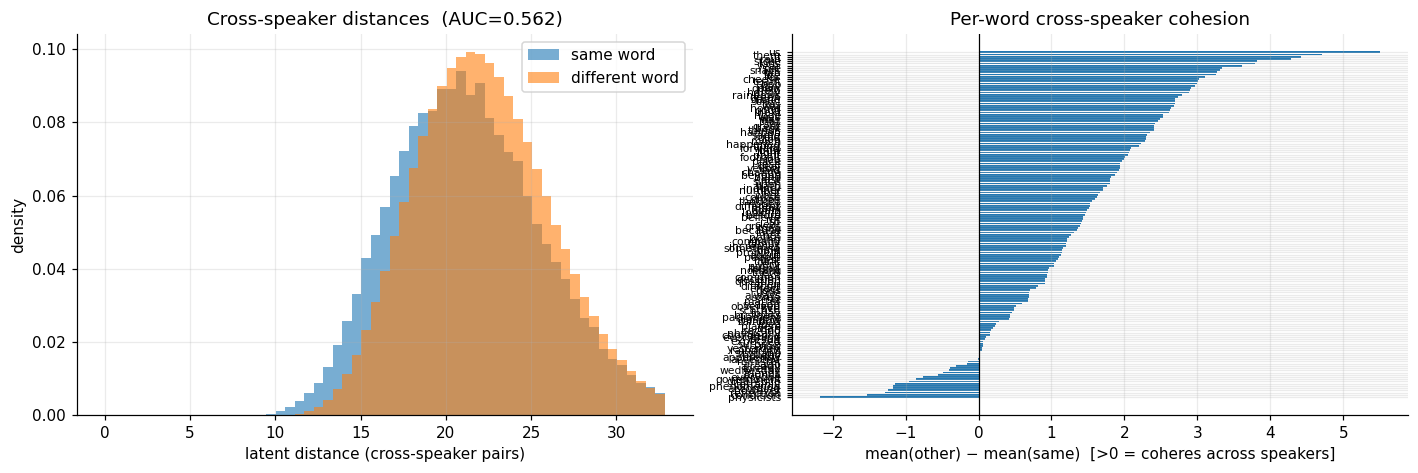

In [9]:
# --- (c/d) cross-speaker same-vs-different-word distances (the robust core) ---
from sklearn.metrics import roc_auc_score, silhouette_score
from scipy.spatial.distance import pdist, squareform

Zws = StandardScaler().fit_transform(Zw)           # standardised, as elsewhere
Dm  = squareform(pdist(Zws, metric="euclidean"))   # (n, n) pairwise distances
iu, ju = np.triu_indices(len(Zw), k=1)
cross = wspk[iu] != wspk[ju]                        # keep only cross-speaker pairs
same_w = wlab[iu] == wlab[ju]
d_cross = Dm[iu, ju][cross]
same_cross = same_w[cross]
print(f"cross-speaker pairs: {same_cross.sum()} same-word | {(~same_cross).sum()} different-word")

# can raw distance alone tell same-word from different-word (across speakers)?
# smaller distance should indicate same word -> score with -distance
auc = roc_auc_score(same_cross.astype(int), -d_cross)
print(f"same-vs-different-word AUC by distance (cross-speaker only): {auc:.3f}  (0.5 = no word signal)")
print(f"mean distance  same-word {d_cross[same_cross].mean():.2f}  vs  "
      f"different-word {d_cross[~same_cross].mean():.2f}")

# cross-speaker word silhouette: word cohesion measured on cross-speaker structure
sil_w = silhouette_score(Zws, wlab)                # standard silhouette over words
print(f"word silhouette (all pairs): {sil_w:+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
b = np.linspace(0, np.percentile(d_cross, 99), 60)
ax[0].hist(d_cross[same_cross],  bins=b, density=True, alpha=0.6, label="same word")
ax[0].hist(d_cross[~same_cross], bins=b, density=True, alpha=0.6, label="different word")
ax[0].set_xlabel("latent distance (cross-speaker pairs)"); ax[0].set_ylabel("density")
ax[0].set_title(f"Cross-speaker distances  (AUC={auc:.3f})"); ax[0].legend()

# per-word: mean cross-speaker distance to same word vs. to other words
rows = []
for c in le_w.classes_:
    m = wlab == c
    if m.sum() < 2: continue
    sub_cross = (wspk[iu] != wspk[ju])
    isc = sub_cross & (wlab[iu] == c) & (wlab[ju] == c)          # same-word cross-spk
    ioc = sub_cross & ((wlab[iu] == c) ^ (wlab[ju] == c))        # this word vs others
    rows.append((c, Dm[iu, ju][isc].mean() if isc.any() else np.nan,
                    Dm[iu, ju][ioc].mean() if ioc.any() else np.nan))
wd = pd.DataFrame(rows, columns=["word", "same", "other"]).dropna()
wd["gap"] = wd["other"] - wd["same"]               # positive => word coheres across speakers
wd = wd.sort_values("gap", ascending=False)
ax[1].barh(range(len(wd)), wd["gap"])
ax[1].set_yticks(range(len(wd))); ax[1].set_yticklabels(wd["word"], fontsize=7)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("mean(other) − mean(same)  [>0 = coheres across speakers]")
ax[1].set_title("Per-word cross-speaker cohesion"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

fraction of latent variance explained by group means (on the word subset):
  speaker : 0.083
  word    : 0.157

If speaker >> word, the geometry is dominated by *who* is speaking, and any
word signal (above) lives in the residual — encoded, but not the dominant axis.


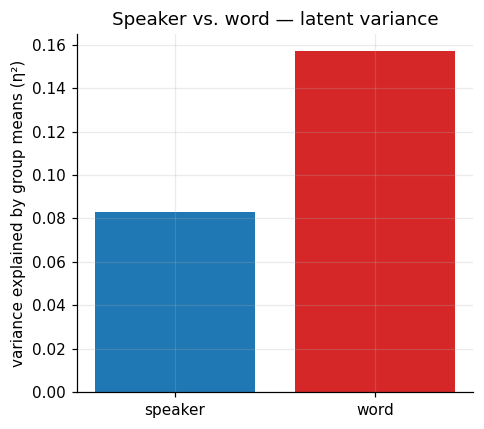

In [10]:
# --- speaker vs. word: which factor explains more latent variance? ---
def between_group_frac(X, labels):
    """Fraction of total variance explained by group means (eta^2, pooled over dims)."""
    Xc = X - X.mean(0)
    tot = (Xc ** 2).sum()
    between = 0.0
    for g in pd.unique(labels):
        m = labels == g
        between += m.sum() * ((X[m].mean(0) - X.mean(0)) ** 2).sum()
    return between / tot

frac_spk  = between_group_frac(Zw, wspk)
frac_word = between_group_frac(Zw, wlab)
print("fraction of latent variance explained by group means (on the word subset):")
print(f"  speaker : {frac_spk:.3f}")
print(f"  word    : {frac_word:.3f}")
print("\nIf speaker >> word, the geometry is dominated by *who* is speaking, and any"
      "\nword signal (above) lives in the residual — encoded, but not the dominant axis.")

plt.figure(figsize=(4.5, 4))
plt.bar(["speaker", "word"], [frac_spk, frac_word],
        color=["#1f77b4", "#d62728"])
plt.ylabel("variance explained by group means (η²)")
plt.title("Speaker vs. word — latent variance"); plt.tight_layout(); plt.show()

## 4 · How to read the results

* **§1** tells you the *effective* size of the latent (active units) and whether the encoder uses the prior. Gender/accent classification can only succeed in the active subspace.
* **§2** — if the mean-difference axis and the logistic axis are well aligned and the traversal flips $P(F)$ smoothly, gender is encoded **linearly along one direction**: clean latent arithmetic. The honest (grouped) AUC is the number to report.
* **§3** — accent is the real test of structure. Compare balanced accuracy to the by-frequency baseline; the confusion matrix shows *which* accents the latent actually separates (often the well-sampled, acoustically distinct ones) vs. those it folds into the majority class.

**Knobs:** `to_matrix` pooling (if your latents are temporal you may not want a plain mean), `THR` for the active-unit cutoff, `MIN_SPK` for which accents to keep, and `C` in the logistic regressions if you want to probe how much regularisation the signal tolerates.